
# CIFAR-10 Image Dataset Analysis

## 1. Loading the Dataset

The CIFAR-10 dataset contains 60,000 labelled RGB images across ten object categories. The dataset is provided in MATLAB format and consists of five training batches and one testing batch.

The dataset will be loaded into Python for inspection, analysis and preparation for CNN image classification.


In [1]:

# Import required libraries

import os
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

# Define the dataset directory

dataset_path = r"C:\Users\luten\cifar-10-batches-mat"

# Display available dataset files

print("Dataset files:")

for file in sorted(os.listdir(dataset_path)):
    print(file)


Dataset files:
batches.meta.mat
data_batch_1.mat
data_batch_2.mat
data_batch_3.mat
data_batch_4.mat
data_batch_5.mat
readme.html
test_batch.mat



## 2. Loading the Training and Testing Data

The CIFAR-10 dataset is divided into five training batches and one testing batch. Each training batch contains 10,000 images, while the testing batch contains another 10,000 images.

The six batches will be loaded and combined to create a single training dataset and a separate testing dataset. The image data and corresponding class labels will be extracted for further analysis.


In [2]:

# Load the five training batches

training_batches = []

for i in range(1, 6):
    file_path = os.path.join(dataset_path, f"data_batch_{i}.mat")
    batch = sio.loadmat(file_path)
    training_batches.append(batch)

# Combine all training images
X_train = np.concatenate(
    [batch['data'] for batch in training_batches],
    axis=0
)

# Combine all training labels
y_train = np.concatenate(
    [batch['labels'].flatten() for batch in training_batches],
    axis=0
)

# Load the testing batch
test_batch = sio.loadmat(
    os.path.join(dataset_path, "test_batch.mat")
)

X_test = test_batch['data']
y_test = test_batch['labels'].flatten()

# Display dataset dimensions
print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("\nTesting data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


Training data shape: (50000, 3072)
Training labels shape: (50000,)

Testing data shape: (10000, 3072)
Testing labels shape: (10000,)



## 3. Dataset Structure and Data Types

This section examines the structure of the loaded training and testing datasets. The data types, pixel value ranges and label values will be inspected to understand how the images are represented and identify any unusual values.

Each image is stored as a flattened array containing 3,072 values, representing its RGB colour channels.


In [3]:

# Inspect the data types

print("DATA TYPES")
print("------------------------------")
print("Training images:", X_train.dtype)
print("Training labels:", y_train.dtype)
print("Testing images:", X_test.dtype)
print("Testing labels:", y_test.dtype)

# Inspect pixel value ranges

print("\nPIXEL VALUE RANGE")
print("------------------------------")
print("Minimum training pixel value:", X_train.min())
print("Maximum training pixel value:", X_train.max())

print("Minimum testing pixel value:", X_test.min())
print("Maximum testing pixel value:", X_test.max())

# Inspect unique class labels

print("\nUNIQUE CLASS LABELS")
print("------------------------------")
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))
print("Number of classes:", len(np.unique(y_train)))


DATA TYPES
------------------------------
Training images: uint8
Training labels: uint8
Testing images: uint8
Testing labels: uint8

PIXEL VALUE RANGE
------------------------------
Minimum training pixel value: 0
Maximum training pixel value: 255
Minimum testing pixel value: 0
Maximum testing pixel value: 255

UNIQUE CLASS LABELS
------------------------------
Training labels: [0 1 2 3 4 5 6 7 8 9]
Testing labels: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10



## 4. Dataset Quality Assessment

The training and testing datasets will be checked for potential data-quality issues.

The assessment will include checking for missing values, invalid pixel values and duplicate images. These checks help determine whether the dataset requires additional cleaning before it is used for image classification.

Duplicate images will be investigated separately within the training and testing datasets.


In [4]:

# Check for missing values

print("MISSING VALUE CHECK")
print("------------------------------")

print("Missing values in training images:",
      np.isnan(X_train).sum())

print("Missing values in testing images:",
      np.isnan(X_test).sum())

print("Missing values in training labels:",
      pd.isna(y_train).sum())

print("Missing values in testing labels:",
      pd.isna(y_test).sum())


# Check for invalid pixel values

print("\nINVALID PIXEL VALUE CHECK")
print("------------------------------")

print("Invalid training pixel values:",
      np.sum((X_train < 0) | (X_train > 255)))

print("Invalid testing pixel values:",
      np.sum((X_test < 0) | (X_test > 255)))


# Check for duplicate images within each dataset

print("\nDUPLICATE IMAGE CHECK")
print("------------------------------")

print("Duplicate training images:",
      len(X_train) - len(np.unique(X_train, axis=0)))

print("Duplicate testing images:",
      len(X_test) - len(np.unique(X_test, axis=0)))


MISSING VALUE CHECK
------------------------------
Missing values in training images: 0
Missing values in testing images: 0
Missing values in training labels: 0
Missing values in testing labels: 0

INVALID PIXEL VALUE CHECK
------------------------------
Invalid training pixel values: 0
Invalid testing pixel values: 0

DUPLICATE IMAGE CHECK
------------------------------
Duplicate training images: 0
Duplicate testing images: 0



## 5. Class Distribution

The CIFAR-10 dataset contains ten image categories. The class distribution will be examined separately for the training and testing datasets to determine how many images belong to each category.


In [5]:

# Load the class names

meta = sio.loadmat(
    os.path.join(dataset_path, "batches.meta.mat")
)

class_names = [
    label[0] for label in meta['label_names'].flatten()
]

# Count images in each class

train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

# Create a class distribution table

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Training Images": train_counts,
    "Testing Images": test_counts
})

print("CLASS DISTRIBUTION")
print("------------------------------")
display(class_distribution)


CLASS DISTRIBUTION
------------------------------


,Class,Training Images,Testing Images
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000



## 6. Visualisation of Class Distribution

A bar chart will be used to visualise the number of images in each category. This provides a visual comparison of the training and testing class distributions.


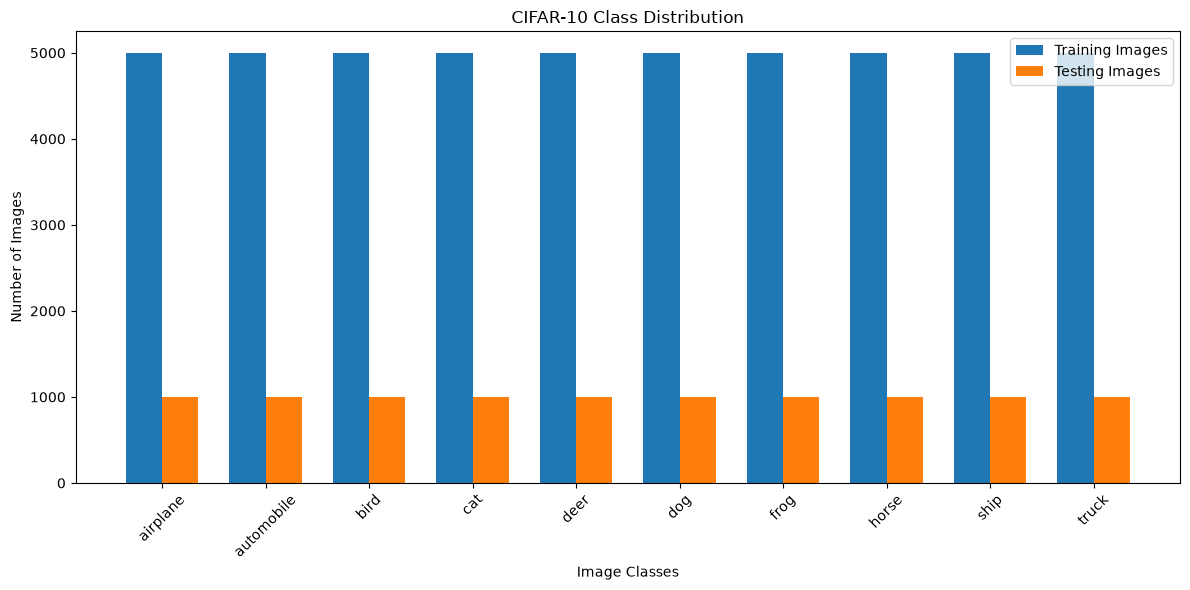

In [6]:

# Plot training and testing class distributions

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, train_counts, width,
        label="Training Images")

plt.bar(x + width/2, test_counts, width,
        label="Testing Images")

plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")

plt.xticks(x, class_names, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 7. Visual Inspection of Sample Images

Sample images from the CIFAR-10 training dataset will be displayed to examine their appearance and verify that the images correspond to their assigned class labels.

Each image will be reconstructed into its original 32 × 32 RGB format.


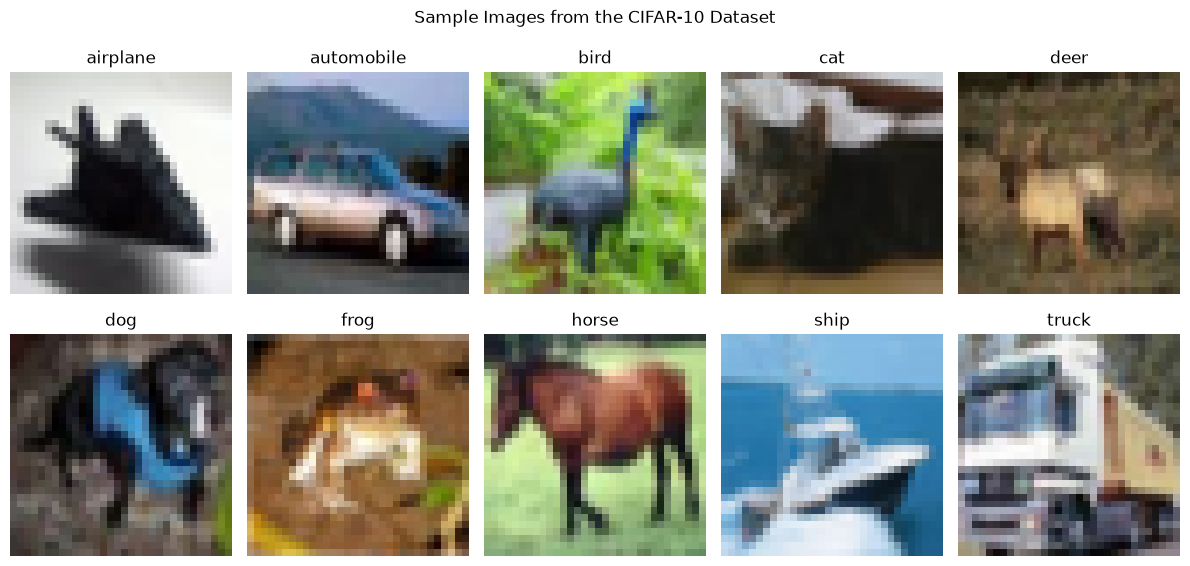

In [7]:

# Display one sample image from each class

plt.figure(figsize=(12, 6))

for class_id in range(10):

    # Find the first image belonging to the class
    image_index = np.where(y_train == class_id)[0][0]

    # Reshape the flattened image into RGB format
    image = X_train[image_index].reshape(3, 32, 32).transpose(1, 2, 0)

    plt.subplot(2, 5, class_id + 1)
    plt.imshow(image)
    plt.title(class_names[class_id])
    plt.axis("off")

plt.suptitle("Sample Images from the CIFAR-10 Dataset")
plt.tight_layout()
plt.show()



## 8. Image Dimensions and Colour Channels

The image dimensions and RGB colour channels will be examined to confirm the structure of the images before preprocessing.

Each CIFAR-10 image is expected to contain 32 pixels in height, 32 pixels in width and three colour channels: Red, Green and Blue.


IMAGE DIMENSIONS
------------------------------
Image shape: (32, 32, 3)
Image height: 32
Image width: 32
Number of colour channels: 3


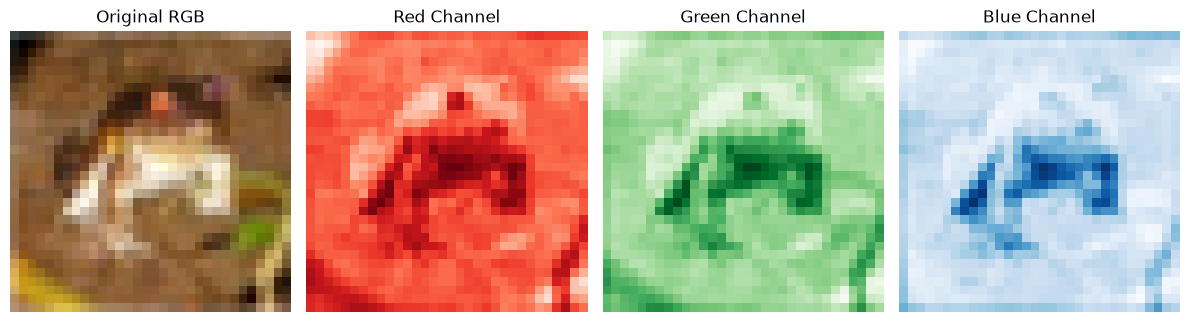

In [8]:

# Reconstruct one training image

sample_image = X_train[0].reshape(3, 32, 32).transpose(1, 2, 0)

print("IMAGE DIMENSIONS")
print("------------------------------")
print("Image shape:", sample_image.shape)
print("Image height:", sample_image.shape[0])
print("Image width:", sample_image.shape[1])
print("Number of colour channels:", sample_image.shape[2])

# Display individual RGB channels

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original RGB")

axes[1].imshow(sample_image[:, :, 0], cmap="Reds")
axes[1].set_title("Red Channel")

axes[2].imshow(sample_image[:, :, 1], cmap="Greens")
axes[2].set_title("Green Channel")

axes[3].imshow(sample_image[:, :, 2], cmap="Blues")
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



## 9. PySpark Dataset Integration

PySpark will be used to perform distributed data analysis on the CIFAR-10 dataset. The image records will be represented in a Spark DataFrame containing the image identifier, dataset split, class label and image-level pixel statistics.

This will allow the training and testing datasets to be examined using Spark SQL and DataFrame operations.


In [9]:

# Import PySpark libraries

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, min, max

# Create a Spark session

spark = SparkSession.builder \
    .appName("CIFAR10_Image_Analysis") \
    .master("local[*]") \
    .getOrCreate()

# Set Spark logging level

spark.sparkContext.setLogLevel("ERROR")

# Display Spark information

print("SPARK ENVIRONMENT")
print("------------------------------")
print("Spark version:", spark.version)
print("Spark application:", spark.sparkContext.appName)
print("Spark master:", spark.sparkContext.master)

# Test the Spark session

spark.range(5).show()


C:\Users\luten\anaconda3\envs\lstm_env\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


SPARK ENVIRONMENT
------------------------------
Spark version: 4.2.0
Spark application: CIFAR10_Image_Analysis
Spark master: local[*]
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+




## 10. Creating the Spark Image Dataset

The training and testing image records will be converted into a structured Spark DataFrame. Image-level pixel statistics will be calculated to support further analysis of the dataset.

The original image arrays will remain unchanged for CNN preprocessing and model development.


In [16]:

# Recreate the Spark DataFrame using the new Spark session

all_records = train_records + test_records

spark_df = spark.createDataFrame(
    all_records,
    schema=schema
)

# Verify the new DataFrame

print("SPARK DATAFRAME VERIFICATION")
print("------------------------------")

print("Total records:", spark_df.count())

print("\nDataset sample:")
spark_df.show(5, truncate=False)

print("\nDataset schema:")
spark_df.printSchema()


SPARK DATAFRAME VERIFICATION
------------------------------
Total records: 60000

Dataset sample:
+--------+-------------+-----------+----------+--------------------+---------------+---------------+
|image_id|dataset_split|class_label|class_name|mean_pixel_intensity|min_pixel_value|max_pixel_value|
+--------+-------------+-----------+----------+--------------------+---------------+---------------+
|0       |Training     |6          |frog      |103.447265625       |0              |255            |
|1       |Training     |9          |truck     |130.34733072916666  |5              |254            |
|2       |Training     |9          |truck     |133.74055989583334  |20             |255            |
|3       |Training     |4          |deer      |80.22428385416667   |4              |234            |
|4       |Training     |1          |automobile|103.47493489583333  |0              |254            |
+--------+-------------+-----------+----------+--------------------+---------------+----------


## 11. Spark Analysis of Dataset Distribution

Spark DataFrame operations will be used to examine the number of records in each dataset split and the distribution of images across the ten classes.

This analysis will verify the dataset composition using PySpark rather than relying only on the initial NumPy calculations.


In [17]:

# Analyse training and testing record counts

print("DATASET SPLIT DISTRIBUTION")
print("------------------------------")

spark_df.groupBy("dataset_split") \
    .count() \
    .orderBy("dataset_split") \
    .show()

# Analyse class distribution by dataset split

print("CLASS DISTRIBUTION USING SPARK")
print("------------------------------")

spark_df.groupBy("dataset_split", "class_name") \
    .count() \
    .orderBy("dataset_split", "class_name") \
    .show(20, truncate=False)


DATASET SPLIT DISTRIBUTION
------------------------------
+-------------+-----+
|dataset_split|count|
+-------------+-----+
|      Testing|10000|
|     Training|50000|
+-------------+-----+

CLASS DISTRIBUTION USING SPARK
------------------------------
+-------------+----------+-----+
|dataset_split|class_name|count|
+-------------+----------+-----+
|Testing      |airplane  |1000 |
|Testing      |automobile|1000 |
|Testing      |bird      |1000 |
|Testing      |cat       |1000 |
|Testing      |deer      |1000 |
|Testing      |dog       |1000 |
|Testing      |frog      |1000 |
|Testing      |horse     |1000 |
|Testing      |ship      |1000 |
|Testing      |truck     |1000 |
|Training     |airplane  |5000 |
|Training     |automobile|5000 |
|Training     |bird      |5000 |
|Training     |cat       |5000 |
|Training     |deer      |5000 |
|Training     |dog       |5000 |
|Training     |frog      |5000 |
|Training     |horse     |5000 |
|Training     |ship      |5000 |
|Training     |truck 


## 12. Spark Analysis of Pixel Intensity

The average, minimum and maximum pixel intensities will be analysed using Spark. This will provide an overview of image brightness and pixel-value variation across the training and testing datasets.

The analysis will also compare the average pixel intensity across the ten image classes.


In [19]:

# Analyse pixel statistics by dataset split

print("PIXEL INTENSITY BY DATASET SPLIT")
print("------------------------------")

spark_df.groupBy("dataset_split").agg(
    avg("mean_pixel_intensity").alias("average_intensity"),
    min("min_pixel_value").alias("minimum_pixel"),
    max("max_pixel_value").alias("maximum_pixel")
).show()

# Analyse average pixel intensity by image class

print("AVERAGE PIXEL INTENSITY BY CLASS")
print("------------------------------")

spark_df.groupBy("class_name").agg(
    avg("mean_pixel_intensity").alias("average_intensity")
).orderBy("class_name").show(truncate=False)


PIXEL INTENSITY BY DATASET SPLIT
------------------------------
+-------------+------------------+-------------+-------------+
|dataset_split| average_intensity|minimum_pixel|maximum_pixel|
+-------------+------------------+-------------+-------------+
|     Training|120.70756512369759|            0|          255|
|      Testing|121.52915475260464|            0|          255|
+-------------+------------------+-------------+-------------+

AVERAGE PIXEL INTENSITY BY CLASS
------------------------------
+----------+------------------+
|class_name|average_intensity |
+----------+------------------+
|airplane  |142.8884889865452 |
|automobile|116.70858648003475|
|bird      |119.52415011935767|
|cat       |116.19248442925354|
|deer      |111.49189133029536|
|dog       |117.7895693359375 |
|frog      |106.69693457031258|
|horse     |119.10765190972225|
|ship      |133.50108230251743|
|truck     |124.54412782118054|
+----------+------------------+




## 13. Visualisation of Pixel Intensity by Class

A bar chart will be used to compare the average pixel intensity across the ten CIFAR-10 image classes. This visualisation will highlight differences in average brightness between the categories.


C:\Users\luten\anaconda3\envs\lstm_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\luten\anaconda3\envs\lstm_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


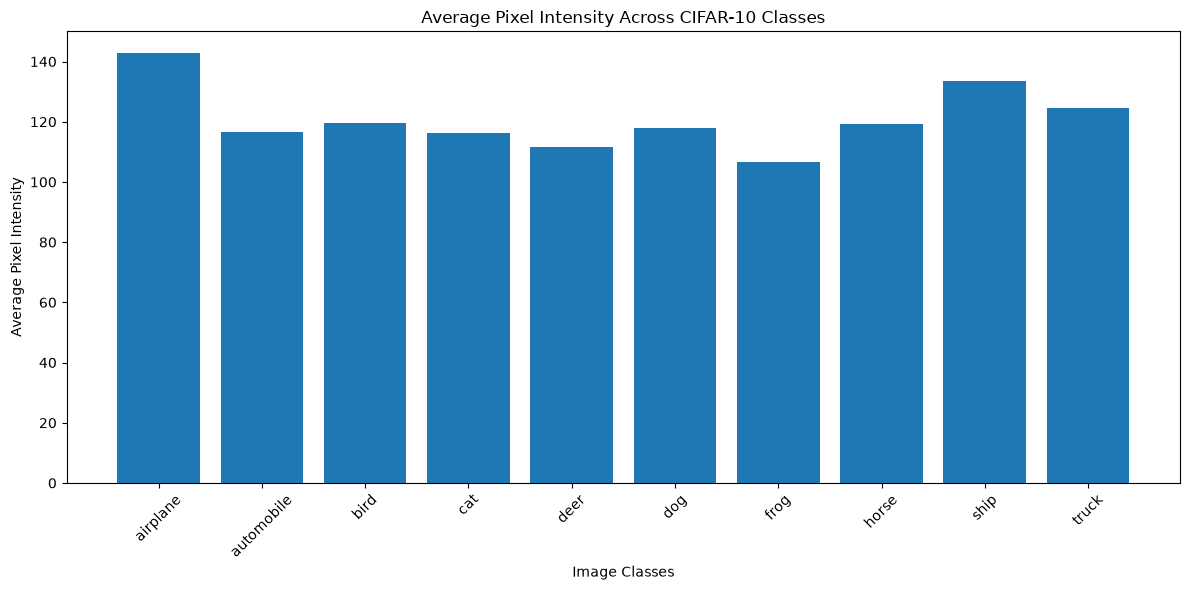

In [20]:

# Calculate average pixel intensity by class using Spark

spark_intensity = spark_df.groupBy("class_name").agg(
    avg("mean_pixel_intensity").alias("average_intensity")
).orderBy("class_name")

# Convert the Spark results for visualisation

intensity_pd = spark_intensity.toPandas()

# Plot average pixel intensity

plt.figure(figsize=(12, 6))

plt.bar(
    intensity_pd["class_name"],
    intensity_pd["average_intensity"]
)

plt.xlabel("Image Classes")
plt.ylabel("Average Pixel Intensity")
plt.title("Average Pixel Intensity Across CIFAR-10 Classes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 14. Image Reshaping and Normalisation

The CIFAR-10 images are currently stored as flattened arrays containing 3,072 pixel values per image.

The images will be reshaped into their original 32 × 32 RGB format. Pixel values will also be normalised from the range 0–255 to 0–1 to support more stable CNN model training.

The original training and testing datasets will be preserved separately.


In [21]:

# Reshape training and testing images

X_train_images = X_train.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
X_test_images = X_test.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

# Normalise pixel values

X_train_normalised = X_train_images.astype("float32") / 255.0
X_test_normalised = X_test_images.astype("float32") / 255.0

# Verify the prepared datasets

print("IMAGE PREPROCESSING VERIFICATION")
print("------------------------------")

print("Training image shape:", X_train_normalised.shape)
print("Testing image shape:", X_test_normalised.shape)

print("\nTraining pixel range:",
      X_train_normalised.min(), "to", X_train_normalised.max())

print("Testing pixel range:",
      X_test_normalised.min(), "to", X_test_normalised.max())

print("\nTraining data type:", X_train_normalised.dtype)
print("Testing data type:", X_test_normalised.dtype)


IMAGE PREPROCESSING VERIFICATION
------------------------------
Training image shape: (50000, 32, 32, 3)
Testing image shape: (10000, 32, 32, 3)

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0

Training data type: float32
Testing data type: float32



## 15. Visual Inspection of Preprocessed Images

A selection of preprocessed images will be displayed to verify that reshaping and normalisation have preserved their visual appearance and class labels.


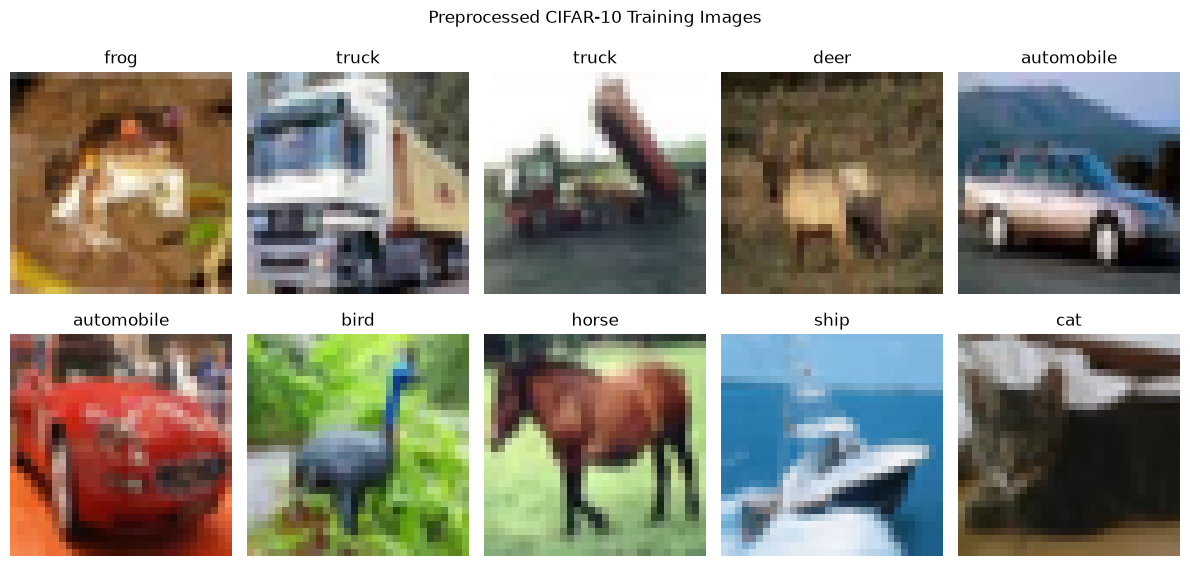

In [22]:

# Display preprocessed training images

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_normalised[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")

plt.suptitle("Preprocessed CIFAR-10 Training Images")
plt.tight_layout()
plt.show()



## 16. Preparation of Class Labels

The CIFAR-10 dataset contains ten target classes represented by integer labels from 0 to 9.

The training and testing labels will be converted into one-hot encoded categorical format. This representation allows the CNN model to predict probabilities across all ten image categories.


In [23]:

# Import the required encoding function

from tensorflow.keras.utils import to_categorical

# Convert labels into one-hot encoded format

y_train_encoded = to_categorical(y_train, num_classes=10)
y_test_encoded = to_categorical(y_test, num_classes=10)

# Verify the encoded labels

print("LABEL ENCODING VERIFICATION")
print("------------------------------")

print("Original training labels shape:", y_train.shape)
print("Encoded training labels shape:", y_train_encoded.shape)

print("\nOriginal testing labels shape:", y_test.shape)
print("Encoded testing labels shape:", y_test_encoded.shape)

print("\nExample original label:", y_train[0])
print("Example encoded label:", y_train_encoded[0])

print("\nNumber of classes:", y_train_encoded.shape[1])


LABEL ENCODING VERIFICATION
------------------------------
Original training labels shape: (50000,)
Encoded training labels shape: (50000, 10)

Original testing labels shape: (10000,)
Encoded testing labels shape: (10000, 10)

Example original label: 6
Example encoded label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

Number of classes: 10



## 17. Final Dataset Preparation Verification

The preprocessed image arrays and encoded labels will be checked to confirm that their dimensions correspond correctly.

This verification ensures that the training and testing datasets are ready to be supplied to the CNN model.


In [26]:

# Verify training and testing dataset compatibility

print("FINAL DATASET VERIFICATION")
print("------------------------------")

print("Training images:", X_train_normalised.shape)
print("Training labels:", y_train_encoded.shape)

print("\nTesting images:", X_test_normalised.shape)
print("Testing labels:", y_test_encoded.shape)

# Check matching record counts

print("\nRECORD COUNT CHECK")
print("------------------------------")

print("Training records match:",
      len(X_train_normalised) == len(y_train_encoded))

print("Testing records match:",
      len(X_test_normalised) == len(y_test_encoded))

# Check for missing or invalid values

print("\nDATA VALIDITY CHECK")
print("------------------------------")

print("Training image NaN values:",
      np.isnan(X_train_normalised).sum())

print("Testing image NaN values:",
      np.isnan(X_test_normalised).sum())

print("Training label NaN values:",
      np.isnan(y_train_encoded).sum())

print("Testing label NaN values:",
      np.isnan(y_test_encoded).sum())


FINAL DATASET VERIFICATION
------------------------------
Training images: (50000, 32, 32, 3)
Training labels: (50000, 10)

Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 10)

RECORD COUNT CHECK
------------------------------
Training records match: True
Testing records match: True

DATA VALIDITY CHECK
------------------------------
Training image NaN values: 0
Testing image NaN values: 0
Training label NaN values: 0
Testing label NaN values: 0



## 18. CNN Model Development

A Convolutional Neural Network (CNN) will be developed to classify images into the ten CIFAR-10 categories.

The model will use convolutional layers to extract image features, pooling layers to reduce spatial dimensions and dense layers to perform classification.


In [27]:

# Import CNN development libraries

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

# Display TensorFlow information

print("CNN DEVELOPMENT ENVIRONMENT")
print("------------------------------")
print("TensorFlow version:", tf.__version__)
print("Number of training images:", X_train_normalised.shape[0])
print("Number of testing images:", X_test_normalised.shape[0])
print("Number of output classes:", len(class_names))


CNN DEVELOPMENT ENVIRONMENT
------------------------------
TensorFlow version: 2.21.0
Number of training images: 50000
Number of testing images: 10000
Number of output classes: 10



## 19. Building the CNN Architecture

A sequential CNN architecture will be created using convolutional, max-pooling, flattening and dense layers.

The convolutional layers will learn visual features such as edges, shapes and patterns. Max-pooling layers will reduce feature-map dimensions, while dropout will help reduce overfitting. The final softmax layer will produce classification probabilities for the ten image categories.


In [28]:

# Build the CNN model

cnn_model = Sequential([

    # First convolutional block
    Conv2D(32, (3, 3), activation="relu",
           padding="same", input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    # Second convolutional block
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    # Third convolutional block
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

# Display the CNN architecture

cnn_model.summary()


C:\Users\luten\anaconda3\envs\lstm_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)


## 20. Compiling the CNN Model

The CNN model will be compiled using the Adam optimiser and categorical cross-entropy loss function.

Categorical accuracy will be used to measure the proportion of correctly classified images during training and evaluation.


In [29]:

# Compile the CNN model

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN MODEL COMPILATION")
print("------------------------------")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Categorical Cross-Entropy")
print("Evaluation metric: Accuracy")
print("\nModel compiled successfully.")


CNN MODEL COMPILATION
------------------------------
Optimizer: Adam
Learning rate: 0.001
Loss function: Categorical Cross-Entropy
Evaluation metric: Accuracy

Model compiled successfully.



## 21. Training the CNN Model

The CNN model will be trained using the preprocessed CIFAR-10 training images and their encoded labels.

A validation subset will be used to monitor the model's performance during training. Training accuracy and loss will be recorded for each epoch to evaluate how the model learns to classify the images.


In [30]:

# Train the CNN model

history = cnn_model.fit(
    X_train_normalised,
    y_train_encoded,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

print("\nCNN training completed.")


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 121ms/step - accuracy: 0.3709 - loss: 1.7060 - val_accuracy: 0.5211 - val_loss: 1.3478
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 93s 138ms/step - accuracy: 0.5283 - loss: 1.3187 - val_accuracy: 0.6164 - val_loss: 1.0754
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 93s 150ms/step - accuracy: 0.6010 - loss: 1.1346 - val_accuracy: 0.6490 - val_loss: 1.0063
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 95s 152ms/step - accuracy: 0.6415 - loss: 1.0208 - val_accuracy: 0.6904 - val_loss: 0.8907
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 93s 149ms/step - accuracy: 0.6734 - loss: 0.9376 - val_accuracy: 0.7042 - val_loss: 0.8425
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 105s 167ms/step - accuracy: 0.6970 - loss: 0.8669 - val_accuracy: 0.7234 - val_loss: 0.8091
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 102s 162ms/step - accuracy: 0.7170 - loss: 0.8087 - val_accuracy: 0.7081 - val_loss: 0.8485
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 103s 164ms/step - accuracy: 0.7358 - loss

 
## 22. Visualisation of CNN Training Performance

The model's training and validation accuracy and loss will be visualised across the ten epochs.

These graphs will help assess learning progress, model convergence and possible overfitting during training.


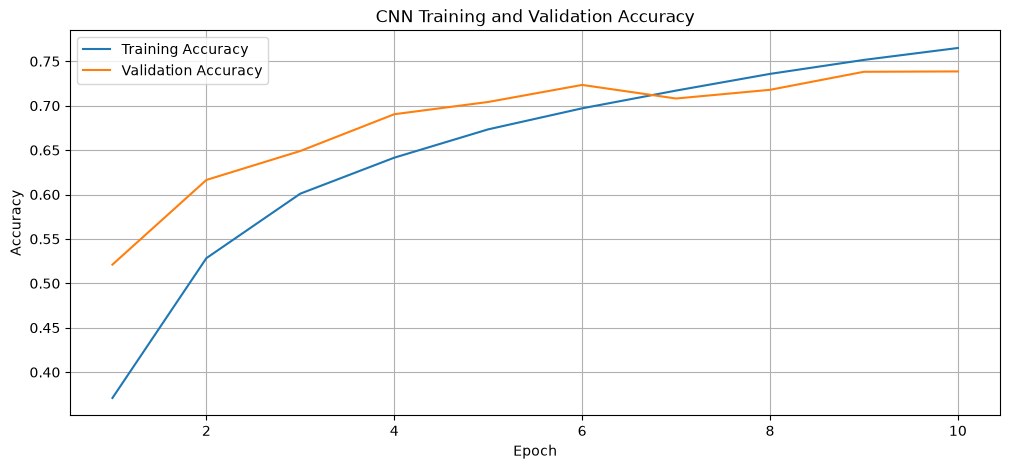

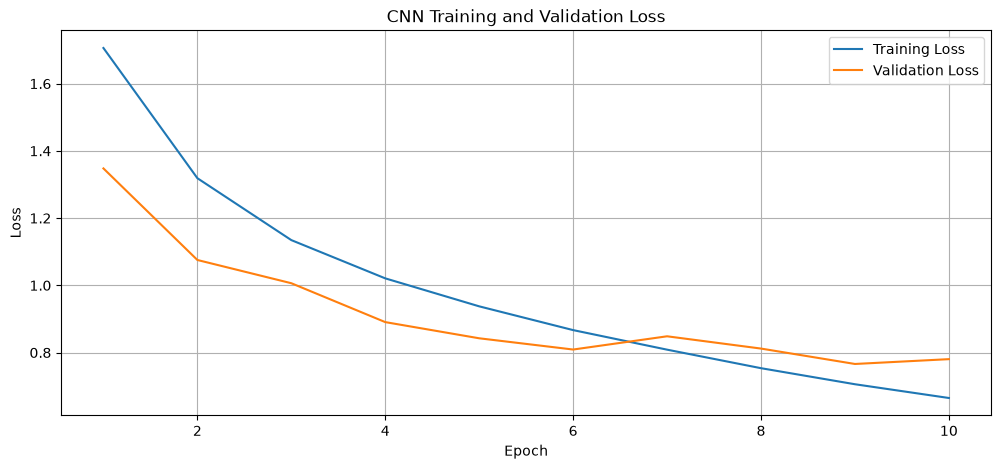

In [31]:

# Extract training history

epochs_range = range(1, len(history.history["accuracy"]) + 1)

# Plot accuracy

plt.figure(figsize=(12, 5))

plt.plot(epochs_range, history.history["accuracy"],
         label="Training Accuracy")

plt.plot(epochs_range, history.history["val_accuracy"],
         label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss

plt.figure(figsize=(12, 5))

plt.plot(epochs_range, history.history["loss"],
         label="Training Loss")

plt.plot(epochs_range, history.history["val_loss"],
         label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()



## 23. CNN Model Evaluation

The trained CNN model will be evaluated using the CIFAR-10 testing dataset.

The testing dataset was kept separate during model training and validation. Test loss and accuracy will be calculated to measure how well the model classifies previously unseen images.


In [32]:

# Evaluate the CNN model on the testing dataset

test_loss, test_accuracy = cnn_model.evaluate(
    X_test_normalised,
    y_test_encoded,
    verbose=1
)

# Display evaluation results

print("\nCNN MODEL EVALUATION RESULTS")
print("------------------------------")
print("Testing loss:", round(test_loss, 4))
print("Testing accuracy:", round(test_accuracy * 100, 2), "%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7286 - loss: 0.7937

CNN MODEL EVALUATION RESULTS
------------------------------
Testing loss: 0.7937
Testing accuracy: 72.86 %



## 24. CNN Image Predictions

The trained CNN model will generate predictions for the testing images. The predicted class labels will be compared with the actual labels to examine the model's classification performance.


In [33]:

# Generate predictions for the testing dataset

y_predictions = cnn_model.predict(X_test_normalised)

# Convert predicted probabilities into class labels

predicted_classes = np.argmax(y_predictions, axis=1)

# Obtain actual class labels

actual_classes = np.argmax(y_test_encoded, axis=1)

# Display the first ten predictions

print("CNN IMAGE PREDICTIONS")
print("------------------------------")

for i in range(10):
    print(
        f"Image {i + 1}: "
        f"Actual = {class_names[actual_classes[i]]}, "
        f"Predicted = {class_names[predicted_classes[i]]}"
    )


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step
CNN IMAGE PREDICTIONS
------------------------------
Image 1: Actual = cat, Predicted = cat
Image 2: Actual = ship, Predicted = ship
Image 3: Actual = ship, Predicted = ship
Image 4: Actual = airplane, Predicted = airplane
Image 5: Actual = frog, Predicted = frog
Image 6: Actual = frog, Predicted = frog
Image 7: Actual = automobile, Predicted = automobile
Image 8: Actual = frog, Predicted = bird
Image 9: Actual = cat, Predicted = cat
Image 10: Actual = automobile, Predicted = automobile



## 25. Visual Comparison of Actual and Predicted Classes

A selection of testing images will be displayed alongside their actual and predicted class labels.

This visual comparison will help identify correctly classified and misclassified images.


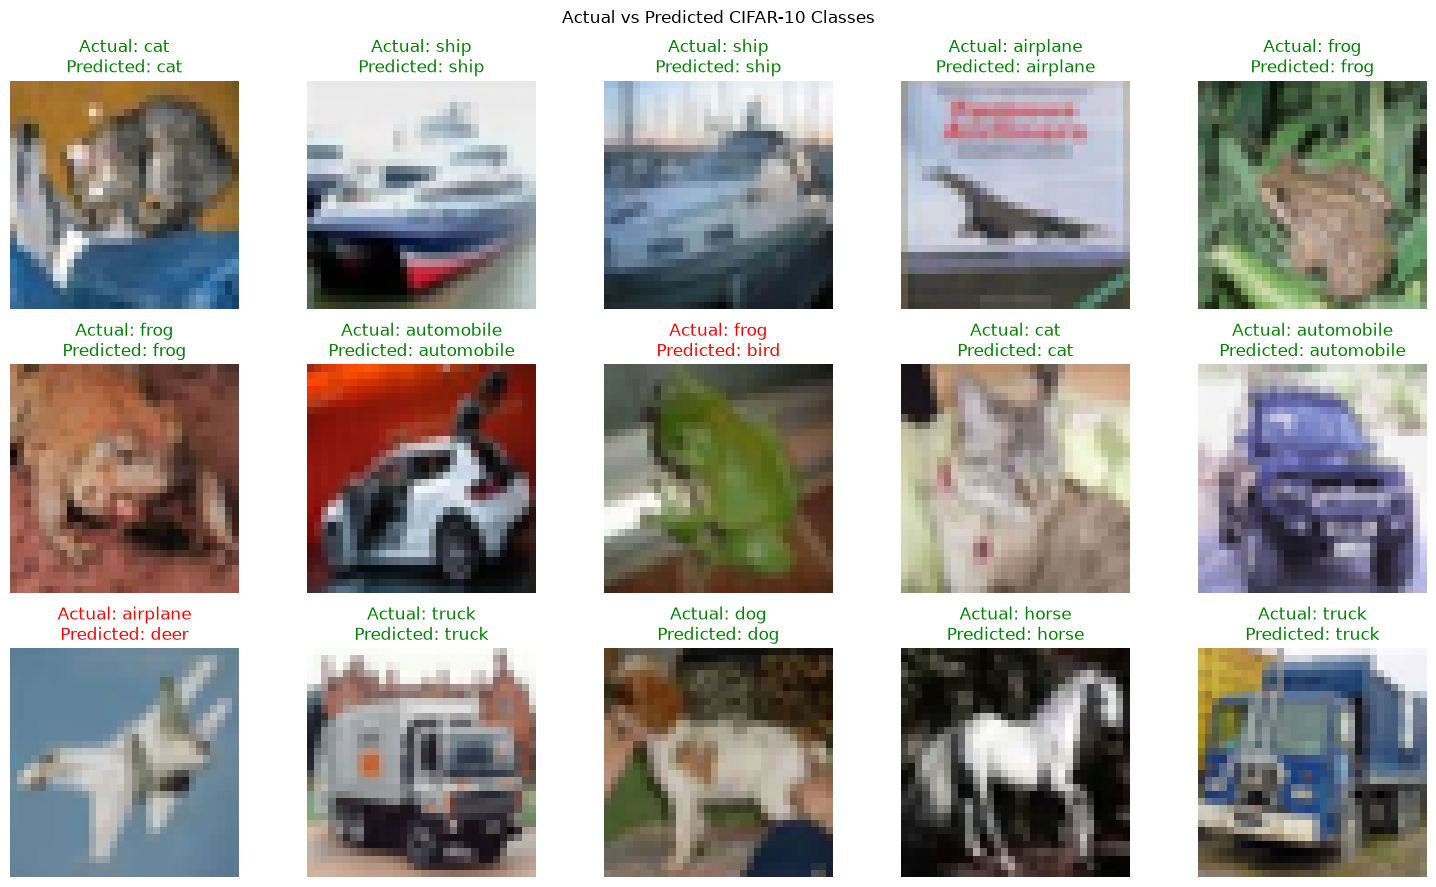

In [35]:

# Display the first 15 testing predictions

plt.figure(figsize=(15, 9))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test_normalised[i])

    actual = class_names[actual_classes[i]]
    predicted = class_names[predicted_classes[i]]

    if actual == predicted:
        title_color = "green"
    else:
        title_color = "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=title_color
    )

    plt.axis("off")

plt.suptitle("Actual vs Predicted CIFAR-10 Classes")
plt.tight_layout()
plt.show()



## 26. Confusion Matrix Analysis

A confusion matrix will be generated to compare the actual class labels with the predicted class labels across the entire testing dataset.

The matrix will show the number of correct and incorrect predictions for each class, helping identify which categories the CNN classifies most and least accurately.


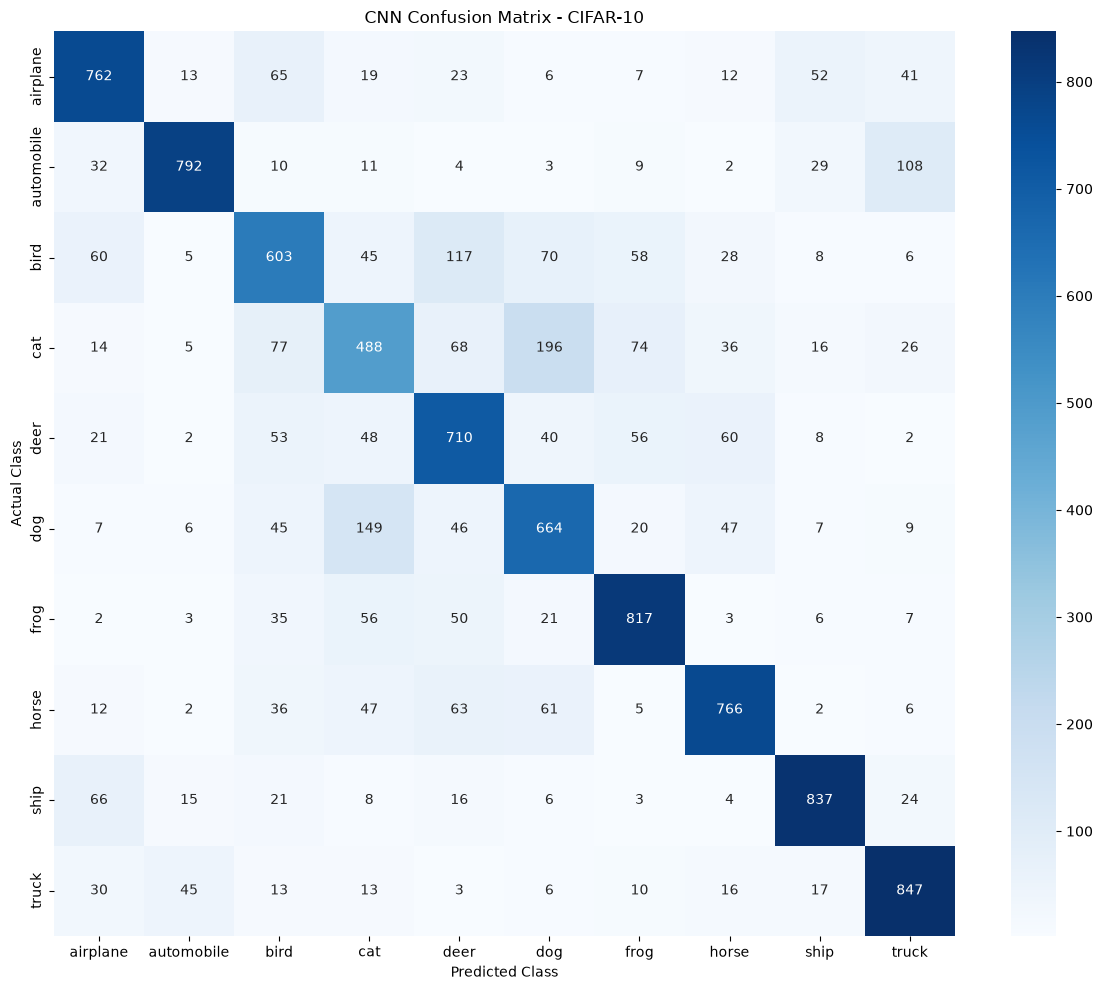

In [36]:

# Import confusion matrix function

from sklearn.metrics import confusion_matrix

# Generate confusion matrix

cm = confusion_matrix(actual_classes, predicted_classes)

# Plot confusion matrix

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix - CIFAR-10")
plt.tight_layout()
plt.show()



## 27. Classification Performance Metrics

Precision, recall and F1-score will be calculated for each CIFAR-10 class.

These metrics provide a detailed assessment of the CNN's classification performance by measuring prediction correctness, identification of actual class members and the balance between precision and recall.


In [37]:

# Import classification report

from sklearn.metrics import classification_report

# Generate classification report

report = classification_report(
    actual_classes,
    predicted_classes,
    target_names=class_names,
    digits=4
)

print("CNN CLASSIFICATION REPORT")
print("------------------------------")
print(report)


CNN CLASSIFICATION REPORT
------------------------------
              precision    recall  f1-score   support

    airplane     0.7575    0.7620    0.7597      1000
  automobile     0.8919    0.7920    0.8390      1000
        bird     0.6294    0.6030    0.6159      1000
         cat     0.5520    0.4880    0.5180      1000
        deer     0.6455    0.7100    0.6762      1000
         dog     0.6188    0.6640    0.6406      1000
        frog     0.7715    0.8170    0.7936      1000
       horse     0.7864    0.7660    0.7761      1000
        ship     0.8523    0.8370    0.8446      1000
       truck     0.7872    0.8470    0.8160      1000

    accuracy                         0.7286     10000
   macro avg     0.7293    0.7286    0.7280     10000
weighted avg     0.7293    0.7286    0.7280     10000




## 28. Classification Performance by Image Class

The F1-scores from the classification report will be visualised to compare the CNN's performance across the ten CIFAR-10 categories.

This visualisation will highlight the classes with stronger and weaker classification results.


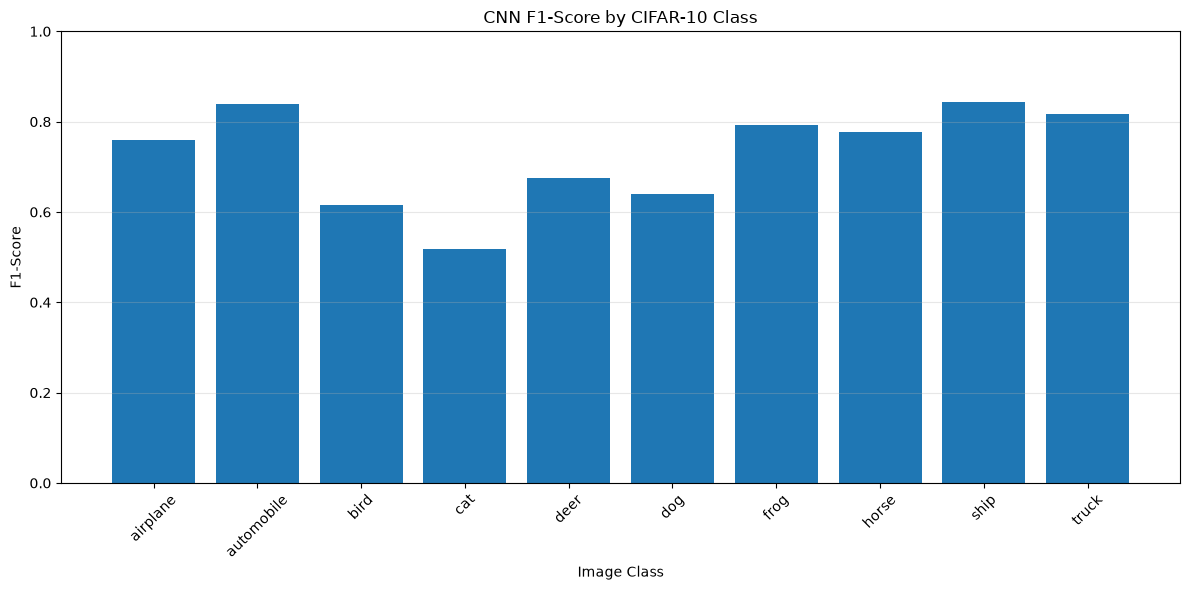

In [38]:

from sklearn.metrics import f1_score

class_f1_scores = f1_score(
    actual_classes,
    predicted_classes,
    average=None
)

plt.figure(figsize=(12, 6))

plt.bar(class_names, class_f1_scores)

plt.xlabel("Image Class")
plt.ylabel("F1-Score")
plt.title("CNN F1-Score by CIFAR-10 Class")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 29. Overall CNN Model Performance

The final training, validation and testing accuracy results will be compared to provide an overview of the CNN model's performance.

This comparison will help assess how well the model learned from the training data and how effectively it performs on unseen testing images.


In [39]:

performance_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Accuracy (%)": [
        history.history["accuracy"][-1] * 100,
        history.history["val_accuracy"][-1] * 100,
        test_accuracy * 100
    ]
})

display(performance_summary.round(2))


,Dataset,Accuracy (%)
0,Training,76.50
1,Validation,73.86
2,Testing,72.86



## 30. Saving the Trained CNN Model

The trained CNN model will be saved in Keras format for future use. Saving the model preserves its architecture, learned weights and training configuration.


In [40]:

# Save the trained CNN model

model_path = "cifar10_cnn_model.keras"

cnn_model.save(model_path)

print("Model saved successfully:", model_path)


Model saved successfully: cifar10_cnn_model.keras



## 31. Loading and Verifying the Saved CNN Model

The saved CNN model will be reloaded to verify that it can be restored and used to classify CIFAR-10 images.

A sample prediction will be generated using the reloaded model.


In [41]:

# Load the saved model

from tensorflow.keras.models import load_model

loaded_model = load_model(model_path)

# Generate a prediction using the loaded model

sample_prediction = loaded_model.predict(
    X_test_normalised[:1],
    verbose=0
)

predicted_label = np.argmax(sample_prediction[0])
actual_label = actual_classes[0]

print("Model loaded successfully.")
print("Actual class:", class_names[actual_label])
print("Predicted class:", class_names[predicted_label])


Model loaded successfully.
Actual class: cat
Predicted class: cat



## 32. Final Spark Dataset Verification

Spark will be used to perform a final verification of the CIFAR-10 dataset records.

The total number of images and the number of records in each dataset split will be confirmed.


In [42]:

print("FINAL SPARK DATASET VERIFICATION")
print("--------------------------------")

print("Total image records:", spark_df.count())

spark_df.groupBy("dataset_split").count().orderBy("dataset_split").show()


FINAL SPARK DATASET VERIFICATION
--------------------------------
Total image records: 60000
+-------------+-----+
|dataset_split|count|
+-------------+-----+
|      Testing|10000|
|     Training|50000|
+-------------+-----+

